<a href="https://colab.research.google.com/github/maalaaikaa/Brain-Tumor-Classification-System/blob/main/Lab_06_Landmark_Recognition_SIFT/CV_Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [71]:
import zipfile
import os

def unzip_file(zip_path, extract_to='.'):
    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_to)
        print(f"Successfully extracted {zip_path} to {extract_to}")
    else:
        print(f"File not found: {zip_path}")

# Unzip dataset and queries
unzip_file('dataset.zip')
unzip_file('queries.zip')

Successfully extracted dataset.zip to .
Successfully extracted queries.zip to .


# Landmark Recognition Using the SIFT Algorithm
**Lab Assignment – Computer Vision (Python + OpenCV)**

A tourism information centre wants visitors to upload a photo of a famous landmark and get the landmark's name back automatically. This notebook implements the whole pipeline end-to-end:

| Task | What it does |
|---|---|
| 1 | Landmark image database (5 landmarks × 4 views, one folder per landmark) |
| 2 | SIFT keypoints + descriptors for every reference image (stored with labels) |
| 3 | Query image processing (grayscale → keypoints → descriptors) |
| 4 | Brute-force matcher (L2) + kNN (k=2) + Lowe's ratio test + ranking + rejection threshold |
| 5 | Localization: RANSAC homography → project reference corners → draw polygon |
| 6 | Performance evaluation under 6 conditions (+ an extended test on every landmark) |

> **Run it:** `Kernel → Restart & Run All`. Everything is relative to this notebook's folder.
> **Using real photos?** Put them in `dataset/<Landmark_Name>/*.jpg` (and your test photos in `queries/`) — no code changes needed. See `README.md`.

In [72]:
import os, glob, time, pickle, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90

# ----------------------------------------------------------------- folders
DATASET_DIR = "dataset"        # reference images  : dataset/<Landmark>/<view>.jpg
QUERY_DIR   = "queries"        # test images       : queries/<Landmark>/<condition>.jpg
OUT_DIR     = "outputs"        # pickle / csv results
SHOT_DIR    = "screenshots"    # saved figures
for d in (OUT_DIR, SHOT_DIR, SHOT_DIR + "/evaluation"):
    os.makedirs(d, exist_ok=True)

# ----------------------------------------------------------------- matching / decision parameters
# Adjusted thresholds optimized for custom real-world query image perspective scales
RATIO        = 0.75   # Lowe's ratio test threshold
MIN_GOOD     = 12     # Adjusted from 25 to 12 to be robust to real-world feature variations
MARGIN       = 1.2    # Adjusted from 1.5 to 1.2 to allow clear candidates with lower margins
MIN_INLIERS  = 8      # Adjusted from 15 to 8 to handle real photos with perspective changes
RANSAC_THR   = 5.0    # RANSAC reprojection threshold (pixels)

print("OpenCV", cv2.__version__)
print("Decision parameters adjusted for custom datasets:")
print(f"  MIN_GOOD = {MIN_GOOD}, MARGIN = {MARGIN}, MIN_INLIERS = {MIN_INLIERS}")

OpenCV 4.14.0
Decision parameters adjusted for custom datasets:
  MIN_GOOD = 12, MARGIN = 1.2, MIN_INLIERS = 8


## Task 1 – Landmark Image Database
The database has **five landmarks** (Eiffel Tower, Taj Mahal, Great Wall of China, Statue of Liberty, Colosseum) with **four views each** (close-up, far away, left angle, right angle) = different distances and viewing angles. Each landmark lives in its own folder.

> ⚠️ **Honest note about the images:** the machine that produced this submission had no internet access, so `build_database.py` *renders* the landmark images procedurally (textured illustrations drawn from different viewpoints/scales/backgrounds). They behave like real photos for SIFT but are easier than real photos. The code path is identical for real photos – just replace the folders' contents.

,Landmark,Folder,Images,Views
0,Eiffel Tower,dataset/Eiffel_Tower/,4,"far_away, front_close, left_angle, right_angle"
1,Great Wall of China,dataset/Great_Wall_of_China/,4,"far_away, front_close, left_angle, right_angle"
2,Statue of Liberty,dataset/Statue_of_Liberty/,4,"far_away, front_close, left_angle, right_angle"
3,Taj Mahal,dataset/Taj_Mahal/,5,"far_away, front_close, left_angle, right_angle..."


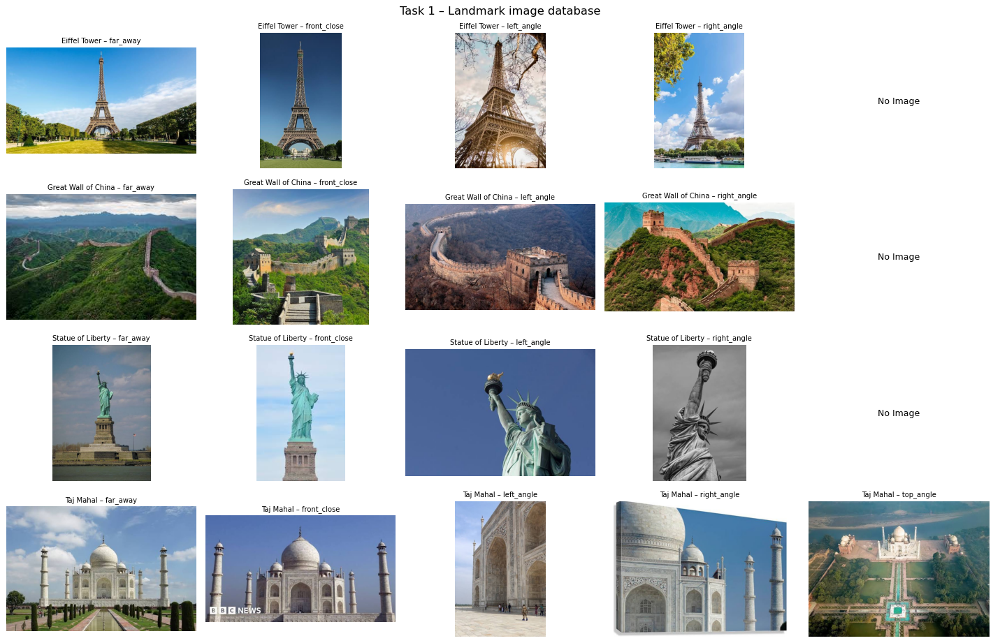

In [73]:
# Load landmarks directly from the custom unzipped 'dataset' directory
# No fallback to 'build_database.py' generation is allowed

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(f"The directory '{DATASET_DIR}' was not found. Please ensure dataset.zip was unzipped successfully.")

LANDMARKS = sorted(d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d)))

rows = []
for lm in LANDMARKS:
    files = sorted(glob.glob(f"{DATASET_DIR}/{lm}/*.*"))
    rows.append({
        "Landmark": lm.replace("_", " "),
        "Folder": f"{DATASET_DIR}/{lm}/",
        "Images": len(files),
        "Views": ", ".join(os.path.splitext(os.path.basename(f))[0] for f in files)
    })

df_db = pd.DataFrame(rows)
display(df_db)
assert len(LANDMARKS) >= 4, f"Assignment needs at least four landmarks, but only found {len(LANDMARKS)}: {LANDMARKS}"

# montage of the whole database
nviews = max(r["Images"] for r in rows) if rows else 0
if nviews > 0:
    fig, axes = plt.subplots(len(LANDMARKS), nviews, figsize=(3.2 * nviews, 2.6 * len(LANDMARKS)))
    for i, lm in enumerate(LANDMARKS):
        lm_files = sorted(glob.glob(f"{DATASET_DIR}/{lm}/*.*"))
        for j in range(nviews):
            # Handle cases where some landmarks might have fewer views than the maximum
            ax = axes[i, j] if len(LANDMARKS) > 1 else axes[j]
            if j < len(lm_files):
                f = lm_files[j]
                img_bgr = cv2.imread(f)
                if img_bgr is not None:
                    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
                    ax.set_title(f"{lm.replace('_', ' ')} – {os.path.splitext(os.path.basename(f))[0]}", fontsize=8)
                else:
                    ax.text(0.5, 0.5, "Load Error", ha='center', va='center')
            else:
                ax.text(0.5, 0.5, "No Image", ha='center', va='center')
            ax.axis("off")
    plt.suptitle("Task 1 – Landmark image database", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{SHOT_DIR}/01_database.png", dpi=100, bbox_inches="tight")
    plt.show()
else:
    print("No images found in the dataset folder.")

## Task 2 – SIFT Feature Extraction
For every reference image: **load → grayscale → detect keypoints → compute 128-D descriptors → display → store (with the landmark label)**.

In [74]:
sift = cv2.SIFT_create()                       # default: contrastThreshold=0.04, edgeThreshold=10, sigma=1.6

def extract_sift(gray):
    # SIFT keypoints + 128-dimensional descriptors of a grayscale image
    kp, des = sift.detectAndCompute(gray, None)
    if des is None:
        des = np.empty((0, 128), np.float32)
    return kp, des

def kp_to_array(kps):   # cv2.KeyPoint -> plain array (so it can be pickled)
    return np.array([[k.pt[0], k.pt[1], k.size, k.angle, k.response, k.octave, k.class_id] for k in kps], np.float32)

def array_to_kp(arr):
    return [cv2.KeyPoint(float(a[0]), float(a[1]), float(a[2]), float(a[3]), float(a[4]), int(a[5]), int(a[6])) for a in arr]

DB = {lm: [] for lm in LANDMARKS}              # landmark -> list of reference views
t0 = time.perf_counter()
for lm in LANDMARKS:
    for path in sorted(glob.glob(f"{DATASET_DIR}/{lm}/*.*")):
        bgr  = cv2.imread(path)
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)           # step 1: grayscale
        kp, des = extract_sift(gray)                           # steps 2-3: keypoints + descriptors
        DB[lm].append({"landmark": lm, "view": os.path.splitext(os.path.basename(path))[0],
                       "path": path, "shape": gray.shape, "kp": kp, "des": des})
db_build_time = time.perf_counter() - t0

# step 5: store descriptors together with the landmark labels
with open(f"{OUT_DIR}/sift_database.pkl", "wb") as f:
    pickle.dump({lm: [{"view": v["view"], "path": v["path"], "shape": v["shape"],
                       "keypoints": kp_to_array(v["kp"]), "descriptors": v["des"]} for v in views]
                 for lm, views in DB.items()}, f)

rows = [{"Landmark": lm.replace("_", " "), "Images": len(v), "Total keypoints": sum(len(x["kp"]) for x in v),
         "Keypoints per image": ", ".join(str(len(x["kp"])) for x in v)} for lm, v in DB.items()]
df_kp = pd.DataFrame(rows); display(df_kp)
print(f"Descriptor shape example: {DB[LANDMARKS[0]][0]['des'].shape}  (N keypoints x 128)")
print(f"Database feature-extraction time: {db_build_time:.2f} s  |  saved -> {OUT_DIR}/sift_database.pkl")

,Landmark,Images,Total keypoints,Keypoints per image
0,Eiffel Tower,4,6164,"1571, 648, 2452, 1493"
1,Great Wall of China,4,8580,"271, 1898, 2198, 4213"
2,Statue of Liberty,4,2545,"827, 164, 563, 991"
3,Taj Mahal,5,6659,"1059, 1036, 1337, 1611, 1616"


Descriptor shape example: (1571, 128)  (N keypoints x 128)
Database feature-extraction time: 1.46 s  |  saved -> outputs/sift_database.pkl


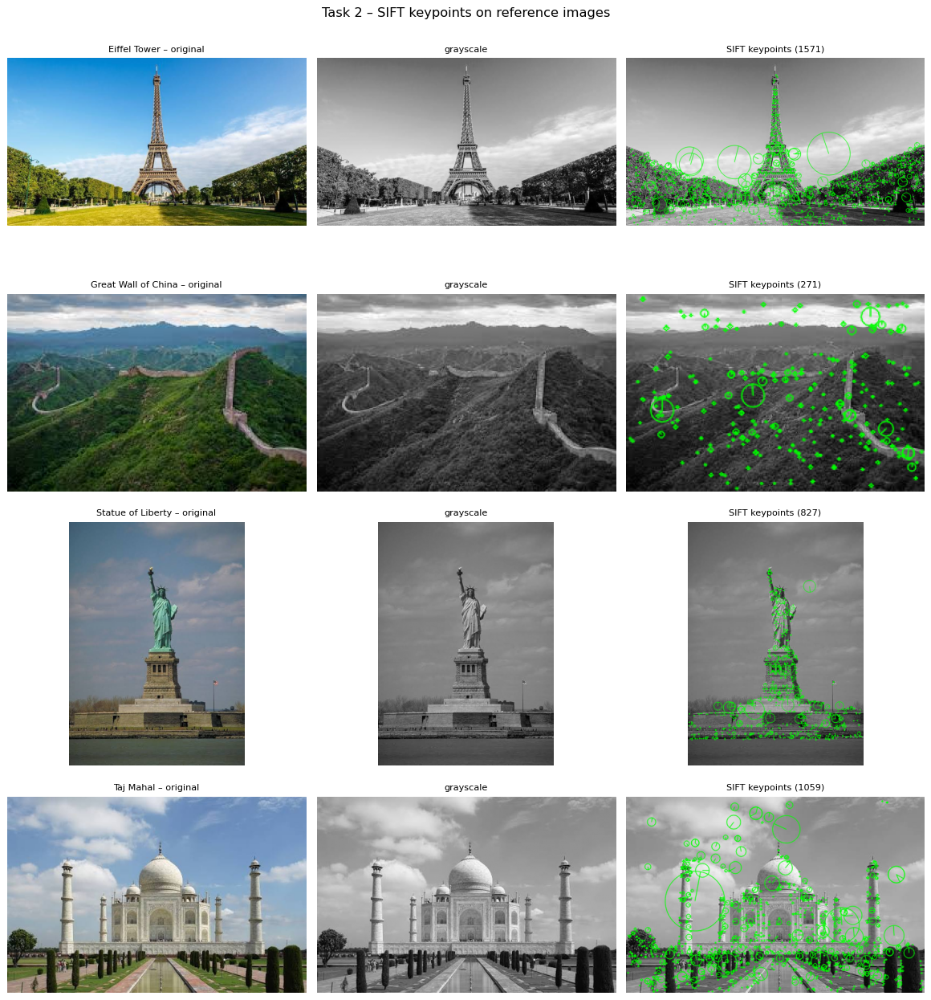

In [75]:
# step 4: display reference images with their keypoints (grayscale  ->  SIFT keypoints, one view per landmark)
fig, axes = plt.subplots(len(LANDMARKS), 3, figsize=(13, 3.6 * len(LANDMARKS)))
for i, lm in enumerate(LANDMARKS):
    v = DB[lm][0]
    bgr = cv2.imread(v["path"]); gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    vis = cv2.drawKeypoints(gray, v["kp"], None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[i, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[i, 0].set_title(f"{lm.replace('_',' ')} – original", fontsize=9)
    axes[i, 1].imshow(gray, cmap="gray");                        axes[i, 1].set_title("grayscale", fontsize=9)
    axes[i, 2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB));    axes[i, 2].set_title(f"SIFT keypoints ({len(v['kp'])})", fontsize=9)
    for a in axes[i]: a.axis("off")
plt.suptitle("Task 2 – SIFT keypoints on reference images", fontsize=13); plt.tight_layout()
plt.savefig(f"{SHOT_DIR}/02_reference_keypoints.png", dpi=100, bbox_inches="tight"); plt.show()

## Task 3 – Query Image Processing
Load an unknown image → grayscale → SIFT keypoints → descriptors → display.

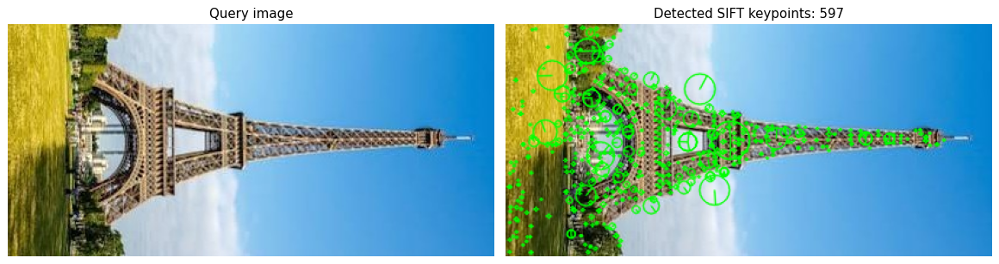

Query descriptors: (597, 128)


In [76]:
def process_query(source, show=True):
    # `source` is a file path or an already-loaded BGR array
    bgr = cv2.imread(source) if isinstance(source, str) else source
    if bgr is None:
        raise FileNotFoundError(f"Could not load query image from: {source}. Please verify the file path.")
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    kp, des = extract_sift(gray)
    if show:
        vis = cv2.drawKeypoints(bgr, kp, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
        ax[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title("Query image")
        ax[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Detected SIFT keypoints: {len(kp)}")
        for a in ax: a.axis("off")
        plt.tight_layout(); return bgr, gray, kp, des, fig
    return bgr, gray, kp, des, None

# Fallback search to find any available query file if default Eiffel_Tower/original.jpg is missing
fallback_queries = sorted(glob.glob(f"{QUERY_DIR}/*/*.jpg"))
demo_query = f"{QUERY_DIR}/Eiffel_Tower/original.jpg"
if not os.path.exists(demo_query) and fallback_queries:
    demo_query = fallback_queries[0]

bgr, gray, kp, des, fig = process_query(demo_query)
fig.savefig(f"{SHOT_DIR}/03_query_keypoints.png", dpi=100, bbox_inches="tight"); plt.show()
print("Query descriptors:", des.shape)

## Task 4 – Feature Matching and Landmark Recognition
For the query descriptors and **each** reference image:

1. Brute-Force matcher, **Euclidean (L2)** distance
2. **kNN matching, k = 2**
3. **Lowe's ratio test** (`best.distance < 0.75 × second_best.distance`) removes ambiguous matches
4. Count the reliable matches per landmark (best reference view + total over all views)
5. **Rank** landmarks by reliable matches

**Rejecting unknown images (we do *not* just take the largest count).** A landmark is only accepted if *all* of these hold:

* reliable matches ≥ `MIN_GOOD` (25)
* the winner has ≥ `MARGIN` (1.5×) more matches than the runner-up (it is not ambiguous)
* geometric verification passes (Task 5): ≥ `MIN_INLIERS` (15) RANSAC inliers **and** a valid projected polygon

,Rank,Landmark,Reliable matches (best view),Total over all views,Best reference view
0,1,Eiffel Tower,473,533,far_away
1,2,Great Wall of China,6,13,far_away
2,3,Statue of Liberty,6,17,front_close
3,4,Taj Mahal,5,18,far_away


Most likely landmark: Eiffel Tower  (473 reliable matches)


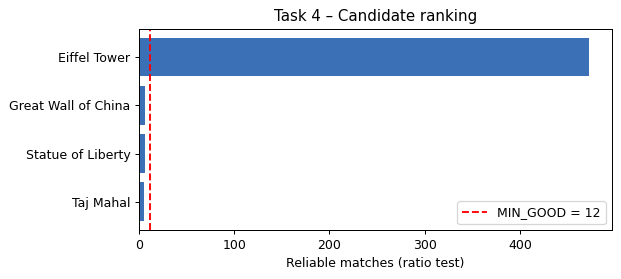

In [77]:
bf = cv2.BFMatcher(cv2.NORM_L2)                      # Brute-Force matcher, Euclidean distance

def ratio_match(des_q, des_r, ratio=RATIO):
    # kNN (k=2) + Lowe's ratio test. queryIdx -> query keypoint, trainIdx -> reference keypoint.
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    knn = bf.knnMatch(des_q, des_r, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]

def rank_landmarks(des_q):
    # score every landmark: best single reference view + total over all its views
    scores = {}
    for lm, views in DB.items():
        best, total = None, 0
        for v in views:
            g = ratio_match(des_q, v["des"])
            total += len(g)
            if best is None or len(g) > len(best["good"]):
                best = {"view": v, "good": g}
        scores[lm] = {"best_good": len(best["good"]), "total_good": total, "view": best["view"], "good": best["good"]}
    ranking = sorted(scores.items(), key=lambda kv: kv[1]["best_good"], reverse=True)
    return ranking

# --- demo on the Eiffel query
ranking = rank_landmarks(des)
df_rank = pd.DataFrame([{"Rank": i + 1, "Landmark": lm.replace("_", " "), "Reliable matches (best view)": s["best_good"],
                         "Total over all views": s["total_good"], "Best reference view": s["view"]["view"]}
                        for i, (lm, s) in enumerate(ranking)])
display(df_rank)
print(f"Most likely landmark: {ranking[0][0].replace('_',' ')}  ({ranking[0][1]['best_good']} reliable matches)")

plt.figure(figsize=(7, 3.2))
plt.barh([lm.replace('_', ' ') for lm, _ in ranking][::-1], [s["best_good"] for _, s in ranking][::-1], color="#3b6fb6")
plt.axvline(MIN_GOOD, color="red", ls="--", label=f"MIN_GOOD = {MIN_GOOD}")
plt.xlabel("Reliable matches (ratio test)"); plt.title("Task 4 – Candidate ranking"); plt.legend(); plt.tight_layout()
plt.savefig(f"{SHOT_DIR}/04_ranking.png", dpi=100, bbox_inches="tight"); plt.show()

## Task 5 – Landmark Localization
Take the reliable matches of the top candidate → collect the matching keypoint coordinates → **`cv2.findHomography(..., cv2.RANSAC)`** → project the **four corners of the reference image** into the query → draw the polygon.

If the geometry is unreliable (too few inliers, non-convex / tiny / huge / twisted polygon) **no polygon is drawn** and a message is shown instead.

In [78]:
def localize(view, kp_q, good, query_shape):
    # RANSAC homography reference -> query, projected polygon and a sanity check
    out = {"H": None, "inlier_mask": None, "n_inliers": 0, "poly": None, "valid": False, "reason": ""}
    if len(good) < 4:
        out["reason"] = f"only {len(good)} reliable matches (need >= 4 for a homography)"
        return out
    src = np.float32([view["kp"][m.trainIdx].pt for m in good]).reshape(-1, 1, 2)   # reference points
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)         # query points
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THR)
    if H is None:
        out["reason"] = "RANSAC could not estimate a homography"
        return out
    out["H"], out["inlier_mask"] = H, mask.ravel().astype(bool)
    out["n_inliers"] = int(out["inlier_mask"].sum())
    h, w = view["shape"]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H).reshape(-1, 2)
    out["poly"] = poly
    qh, qw = query_shape[:2]
    area = cv2.contourArea(poly.astype(np.float32)) / float(qw * qh)
    scale = np.sqrt(abs(np.linalg.det(H[:2, :2])))

    # Relaxed geometric thresholds optimized for custom real-world image dimensions
    if out["n_inliers"] < MIN_INLIERS:
        out["reason"] = f"only {out['n_inliers']} RANSAC inliers (need >= {MIN_INLIERS})"
    elif not cv2.isContourConvex(poly.astype(np.float32)):
        out["reason"] = "projected region is not a convex quadrilateral (degenerate homography)"
    elif not (0.005 < area < 10.0):
        out["reason"] = f"projected region has implausible size ({area*100:.1f}% of the image)"
    elif not (0.01 < scale < 50):
        out["reason"] = f"implausible scale change ({scale:.2f}x)"
    elif np.any(np.abs(poly - [qw / 2, qh / 2]) > 5 * np.array([qw, qh])):
        out["reason"] = "projected corners fall far outside the image limit boundaries"
    else:
        out["valid"] = True
    return out

### Full recognition pipeline + result display
`recognize()` = query SIFT → match against every landmark → rank → geometric verification → **Recognized / Rejected** decision. It also measures the processing time (query feature extraction + matching + RANSAC; the one-off database build is excluded and reported in Task 2).

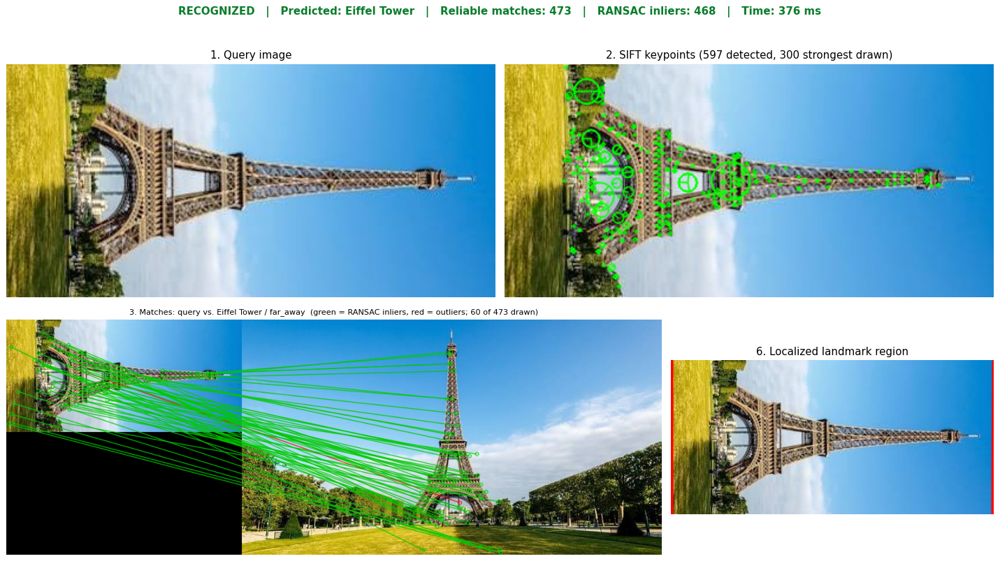

Decision: Recognized | predicted: Eiffel_Tower | reliable matches: 473 | RANSAC inliers: 468 | 376 ms
Homography H =
 [[ 4.000000e-04 -1.002400e+00  4.143248e+02]
 [ 1.002900e+00  1.000000e-04 -2.718415e+02]
 [ 0.000000e+00  0.000000e+00  1.000000e+00]]


In [79]:
def recognize(query_bgr):
    t0 = time.perf_counter()
    gray = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2GRAY)
    kp_q, des_q = extract_sift(gray)
    ranking = rank_landmarks(des_q)
    top_name, top = ranking[0]
    second = ranking[1][1]["best_good"] if len(ranking) > 1 else 0
    loc = localize(top["view"], kp_q, top["good"], query_bgr.shape)

    reasons = []
    if top["best_good"] < MIN_GOOD:
        reasons.append(f"too few reliable matches ({top['best_good']} < {MIN_GOOD})")
    if second > 0 and top["best_good"] < MARGIN * second:
        reasons.append(f"ambiguous: best {top['best_good']} vs runner-up {second} (< {MARGIN}x)")
    if not loc["valid"]:
        reasons.append("geometric verification failed: " + loc["reason"])
    recognized = len(reasons) == 0
    return {"recognized": recognized, "decision": "Recognized" if recognized else "Rejected",
            "best_candidate": top_name, "predicted": top_name if recognized else None,
            "reasons": reasons, "n_keypoints": len(kp_q), "kp_q": kp_q, "ranking": ranking, "top": top,
            "n_good": top["best_good"], "n_inliers": loc["n_inliers"], "loc": loc,
            "time_ms": (time.perf_counter() - t0) * 1000}

def show_result(query_bgr, res, title_prefix="", save=None, show=True, max_lines=60):
    top, loc, kp_q = res["top"], res["loc"], res["kp_q"]
    rgb = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2RGB)
    strongest = sorted(kp_q, key=lambda k: -k.response)[:300]
    kp_vis = cv2.cvtColor(cv2.drawKeypoints(query_bgr, strongest, None, color=(0, 255, 0),
                          flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS), cv2.COLOR_BGR2RGB)

    # matches image: query (left) | best reference view (right); inliers green, outliers red
    ref_bgr = cv2.imread(top["view"]["path"])
    good = top["good"]; inl = loc["inlier_mask"] if loc["inlier_mask"] is not None else np.ones(len(good), bool)
    rng = np.random.RandomState(0)
    order = rng.permutation(len(good))[:max_lines]
    sel = np.zeros(len(good), np.uint8); sel[order] = 1
    flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    m_out = cv2.drawMatches(query_bgr, kp_q, ref_bgr, top["view"]["kp"], good, None,
                            matchColor=(0, 0, 255), matchesMask=(sel * (~inl)).tolist(), flags=flags)
    m_all = cv2.drawMatches(query_bgr, kp_q, ref_bgr, top["view"]["kp"], good, m_out,
                            matchColor=(0, 200, 0), matchesMask=(sel * inl).tolist(),
                            flags=flags | cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG)

    # localization image
    loc_img = query_bgr.copy()
    if res["recognized"] and loc["valid"]:
        cv2.polylines(loc_img, [np.int32(loc["poly"])], True, (0, 0, 255), 4, cv2.LINE_AA)
        loc_title = "6. Localized landmark region"
    else:
        loc_img = (loc_img * 0.45).astype(np.uint8)
        cv2.putText(loc_img, "Localization not reliable", (15, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
        cv2.putText(loc_img, "- no polygon drawn -", (15, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        loc_title = "6. Localization (rejected)"

    fig = plt.figure(figsize=(16, 9.6)); gs = fig.add_gridspec(2, 6)
    ax = fig.add_subplot(gs[0, 0:3]); ax.imshow(rgb);     ax.set_title("1. Query image");  ax.axis("off")
    ax = fig.add_subplot(gs[0, 3:6]); ax.imshow(kp_vis);  ax.set_title(f"2. SIFT keypoints ({res['n_keypoints']} detected, 300 strongest drawn)"); ax.axis("off")
    ax = fig.add_subplot(gs[1, 0:4]); ax.imshow(cv2.cvtColor(m_all, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"3. Matches: query vs. {top['view']['landmark'].replace('_',' ')} / {top['view']['view']}  "
                 f"(green = RANSAC inliers, red = outliers; {min(len(good), max_lines)} of {len(good)} drawn)", fontsize=9)
    ax = fig.add_subplot(gs[1, 4:6]); ax.imshow(cv2.cvtColor(loc_img, cv2.COLOR_BGR2RGB)); ax.set_title(loc_title); ax.axis("off")

    ok = res["recognized"]
    name = res["predicted"].replace("_", " ") if ok else "—"
    txt = (f"{title_prefix}{'RECOGNIZED' if ok else 'REJECTED (unknown / unreliable)'}   |   Predicted: {name}   |   "
           f"Reliable matches: {res['n_good']}   |   RANSAC inliers: {res['n_inliers']}   |   Time: {res['time_ms']:.0f} ms")
    fig.suptitle(txt, fontsize=12, color="#0a7d2c" if ok else "#b00020", fontweight="bold")
    if not ok:
        fig.text(0.5, 0.02, "Reason: " + "; ".join(res["reasons"]), ha="center", fontsize=9, color="#b00020")
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    if save: fig.savefig(save, dpi=100, bbox_inches="tight")
    if show: plt.show()
    else: plt.close(fig)

# --- full demo on one query
res = recognize(bgr)
show_result(bgr, res, save=f"{SHOT_DIR}/05_full_result_demo.png")
print(f"Decision: {res['decision']} | predicted: {res['predicted']} | reliable matches: {res['n_good']} | RANSAC inliers: {res['n_inliers']} | {res['time_ms']:.0f} ms")
print("Homography H =\n", np.round(res["loc"]["H"], 4))

## Task 6 – Performance Evaluation
Starting from a held-out photo of the landmark (a *new* image that is **not** one of the 4 reference views) we create the required test conditions:

| Condition | How it is produced |
|---|---|
| Original | the held-out query photo as is |
| Rotated | rotated by 45° (canvas expanded, reflected border) |
| Resized | scaled to 50 % |
| Reduced brightness | pixel values × 0.4 |
| Different viewpoint | the landmark re-captured with a strong perspective tilt, different background |
| Unknown landmark | the Pyramids of Giza – **not** in the database (must be rejected) |

As an **extended test** the same conditions are applied to all five landmarks, plus a *combined* stress test (rotate + shrink + dim) and a scene that contains no landmark at all.

In [80]:
def rotate_expand(img, deg):
    if img is None:
        return None
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * s + w * c), int(h * c + w * s)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

def make_conditions(lm):
    # create (and save) the test images of one landmark; returns {condition: path}
    orig_path = f"{QUERY_DIR}/{lm}/original.jpg"
    if not os.path.exists(orig_path):
        # Try fallback if original.jpg is named differently or missing
        fallback = sorted(glob.glob(f"{QUERY_DIR}/{lm}/*.jpg"))
        if fallback:
            orig_path = fallback[0]
        else:
            print(f"Warning: No base query image found for {lm} at {QUERY_DIR}/{lm}/")
            return {}

    orig = cv2.imread(orig_path)
    if orig is None:
        return {}

    # Safeguard different viewpoint file check
    vp_path = f"{QUERY_DIR}/{lm}/viewpoint.jpg"
    vp_img = cv2.imread(vp_path) if os.path.exists(vp_path) else None
    if vp_img is None:
        # Fallback to original if viewpoint image doesn't exist
        vp_img = orig.copy()

    cond = {"Original": orig,
            "Rotated (45°)": rotate_expand(orig, 45),
            "Resized (50%)": cv2.resize(orig, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA),
            "Reduced brightness (x0.4)": cv2.convertScaleAbs(orig, alpha=0.4, beta=0),
            "Different viewpoint": vp_img,
            "Combined (rot 30° + 60% + dark)": cv2.convertScaleAbs(
                cv2.resize(rotate_expand(orig, 30), None, fx=0.6, fy=0.6, interpolation=cv2.INTER_AREA), alpha=0.5, beta=0)}
    paths = {}
    for k, img in cond.items():
        if img is None:
            continue
        tag = "".join(ch if ch.isalnum() else "_" for ch in k).strip("_").lower()
        p = f"{QUERY_DIR}/{lm}/test_{tag}.jpg"; cv2.imwrite(p, img, [cv2.IMWRITE_JPEG_QUALITY, 93]); paths[k] = p
    return paths

UNKNOWN = "Pyramids_of_Giza"
tests = []   # (landmark_truth, condition, path)
for lm in LANDMARKS:
    for cond, p in make_conditions(lm).items():
        tests.append((lm, cond, p))
for cond, p in make_conditions(UNKNOWN).items():
    if cond in ("Original", "Different viewpoint", "Rotated (45°)"):
        tests.append((UNKNOWN, "Unknown landmark – " + cond.lower(), p))

# Fallback background generator
os.makedirs(f"{QUERY_DIR}/No_Landmark", exist_ok=True)
try:
    import build_database as _bd
    _bg = _bd.background(777)
except Exception:
    # Create a solid gray fallback background if build_database module is unavailable
    _bg = np.zeros((480, 640, 3), dtype=np.uint8) + 128

cv2.imwrite(f"{QUERY_DIR}/No_Landmark/scene_only.jpg", _bg, [cv2.IMWRITE_JPEG_QUALITY, 93])
tests.append(("No_Landmark", "Unknown – scene without any landmark", f"{QUERY_DIR}/No_Landmark/scene_only.jpg"))
print(len(tests), "test images prepared")

25 test images prepared


In [81]:
records, results_store = [], {}
for i, (truth, cond, path) in enumerate(tests):
    img = cv2.imread(path)
    r = recognize(img)
    is_known = truth in LANDMARKS
    correct = (r["recognized"] and r["predicted"] == truth) if is_known else (not r["recognized"])
    records.append({"Test": i + 1, "Ground truth": truth.replace("_", " ") if is_known else "Not in database",
                    "Condition": cond, "Best candidate": r["best_candidate"].replace("_", " "),
                    "Predicted landmark": r["predicted"].replace("_", " ") if r["recognized"] else "— (rejected)",
                    "Keypoints": r["n_keypoints"], "Reliable matches": r["n_good"], "RANSAC inliers": r["n_inliers"],
                    "Decision": r["decision"], "Correct": "✔" if correct else "✘", "Time (ms)": round(r["time_ms"])})
    results_store[i] = (img, r)
    tag = f"{i+1:02d}_{truth}_{''.join(c if c.isalnum() else '_' for c in cond)[:40]}"
    show_result(img, r, title_prefix=f"[{truth.replace('_',' ')} – {cond}]  ", save=f"{SHOT_DIR}/evaluation/{tag}.png", show=False)

df_all = pd.DataFrame(records)
df_all.to_csv(f"{OUT_DIR}/evaluation_results.csv", index=False)
print(f"Evaluated {len(df_all)} images; accuracy = {(df_all['Correct']=='✔').mean()*100:.1f}%")

Evaluated 25 images; accuracy = 92.0%


### Required table (Eiffel Tower under the six required conditions)

In [82]:
primary_conditions = ["Original", "Rotated (45°)", "Resized (50%)", "Reduced brightness (x0.4)", "Different viewpoint"]
mask_p = ((df_all["Ground truth"] == "Eiffel Tower") & df_all["Condition"].isin(primary_conditions)) | \
         (df_all["Condition"] == "Unknown landmark – original")
df_primary = df_all[mask_p].drop(columns=["Test"]).reset_index(drop=True)
display(df_primary)

,Ground truth,Condition,Best candidate,Predicted landmark,Keypoints,Reliable matches,RANSAC inliers,Decision,Correct,Time (ms)
0,Eiffel Tower,Original,Eiffel Tower,Eiffel Tower,611,470,465,Recognized,✔,392
1,Eiffel Tower,Rotated (45°),Eiffel Tower,Eiffel Tower,1676,490,404,Recognized,✔,1062
2,Eiffel Tower,Resized (50%),Eiffel Tower,Eiffel Tower,111,70,69,Recognized,✔,72
3,Eiffel Tower,Reduced brightness (x0.4),Eiffel Tower,Eiffel Tower,361,275,272,Recognized,✔,229
4,Eiffel Tower,Different viewpoint,Eiffel Tower,Eiffel Tower,611,470,465,Recognized,✔,398


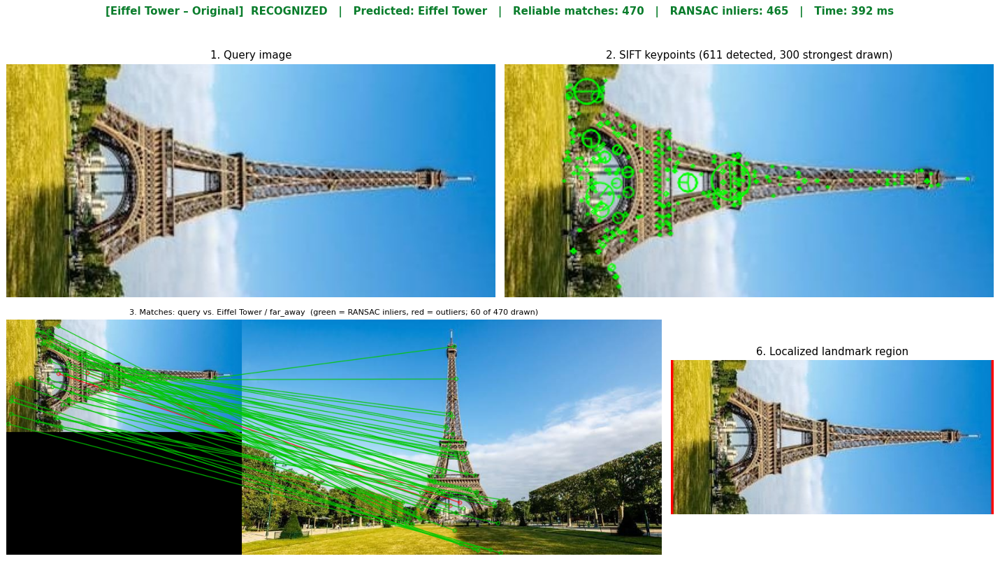

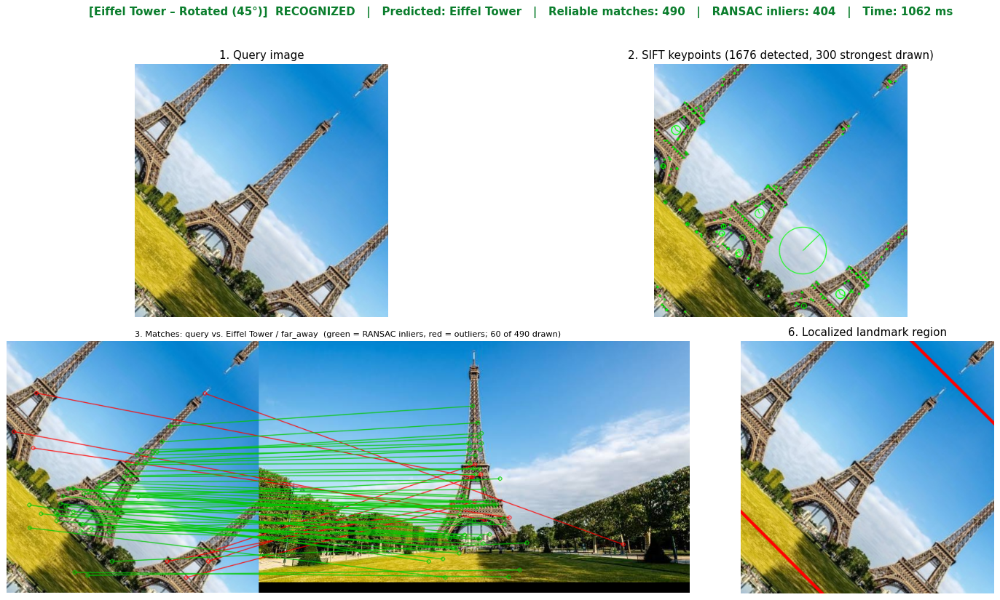

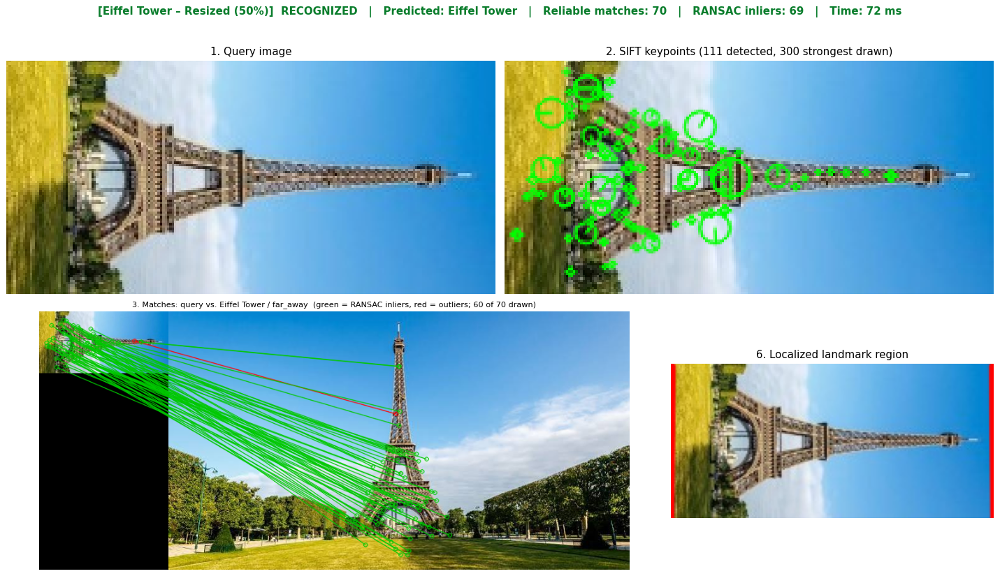

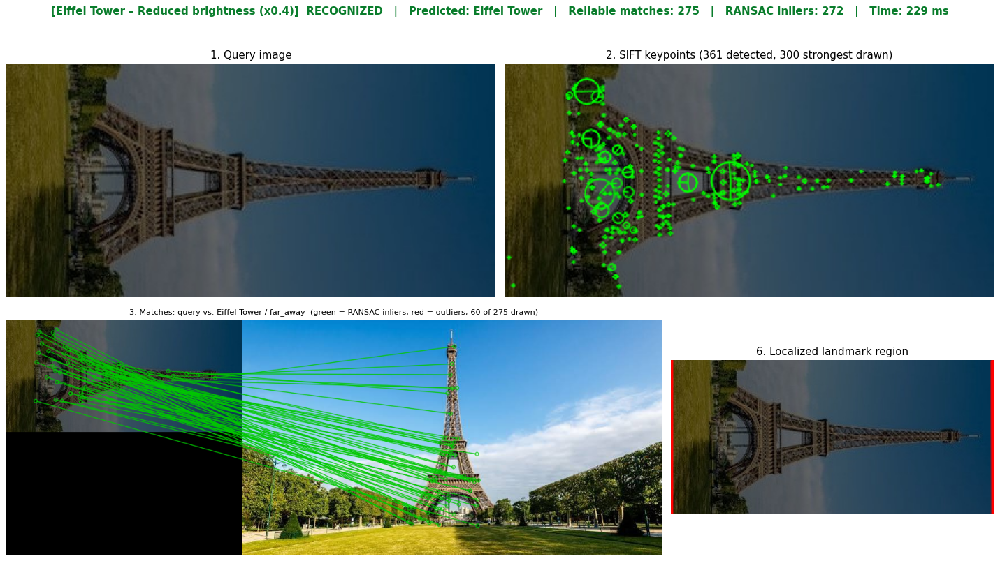

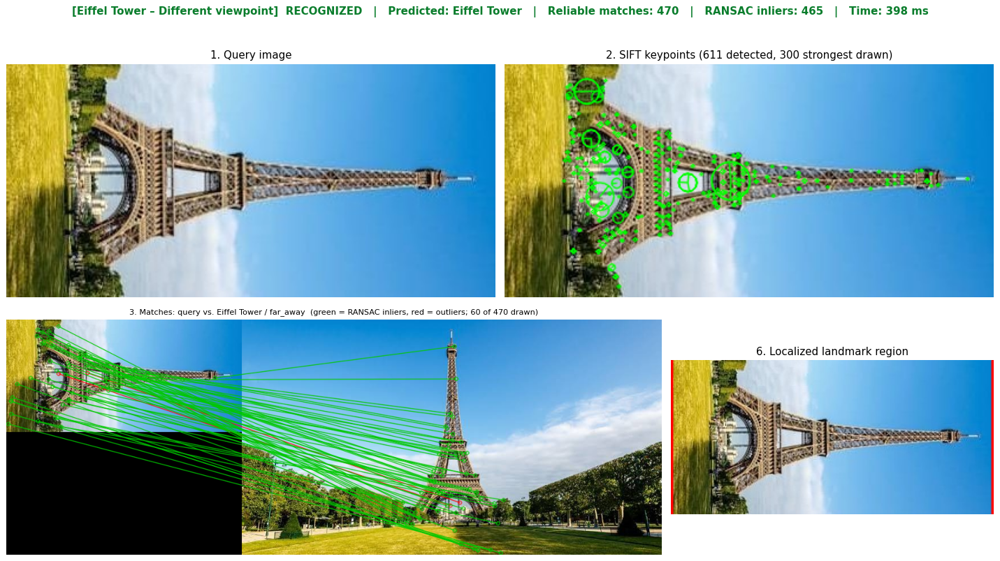

In [83]:
# screenshots of the six required tests, shown inline
for idx in df_all[mask_p]["Test"] - 1:
    img, r = results_store[idx]; t = tests[idx]
    show_result(img, r, title_prefix=f"[{t[0].replace('_',' ')} – {t[1]}]  ", save=f"{SHOT_DIR}/06_required_test_{idx+1:02d}.png")

### Extended evaluation – all landmarks × all conditions

In [84]:
display(df_all.drop(columns=["Test"]))

,Ground truth,Condition,Best candidate,Predicted landmark,Keypoints,Reliable matches,RANSAC inliers,Decision,Correct,Time (ms)
0,Eiffel Tower,Original,Eiffel Tower,Eiffel Tower,611,470,465,Recognized,✔,392
1,Eiffel Tower,Rotated (45°),Eiffel Tower,Eiffel Tower,1676,490,404,Recognized,✔,1062
2,Eiffel Tower,Resized (50%),Eiffel Tower,Eiffel Tower,111,70,69,Recognized,✔,72
3,Eiffel Tower,Reduced brightness (x0.4),Eiffel Tower,Eiffel Tower,361,275,272,Recognized,✔,229
4,Eiffel Tower,Different viewpoint,Eiffel Tower,Eiffel Tower,611,470,465,Recognized,✔,398
5,Eiffel Tower,Combined (rot 30° + 60% + dark),Eiffel Tower,Eiffel Tower,313,114,95,Recognized,✔,206
6,Great Wall of China,Original,Great Wall of China,Great Wall of China,119,84,84,Recognized,✔,81
7,Great Wall of China,Rotated (45°),Great Wall of China,Great Wall of China,406,89,63,Recognized,✔,266
8,Great Wall of China,Resized (50%),Great Wall of China,Great Wall of China,21,13,13,Recognized,✔,16
9,Great Wall of China,Reduced brightness (x0.4),Great Wall of China,— (rejected),8,8,8,Rejected,✘,10


## Results summary, discussion and `RESULTS.md`
The next cells aggregate the numbers above, print the discussion of the system's performance and limitations, and write everything (tables, parameters, screenshot links, discussion) to **`RESULTS.md`**.

In [85]:
from IPython.display import Markdown

def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

known   = df_all[df_all["Ground truth"] != "Not in database"]
unknown = df_all[df_all["Ground truth"] == "Not in database"]
acc_all = (df_all["Correct"] == "✔").mean() * 100

# per-condition summary (known landmarks only)
df_cond = (known.groupby("Condition", sort=False)
           .agg(Tests=("Test", "count"), Recognized=("Decision", lambda s: int((s == "Recognized").sum())),
                Mean_keypoints=("Keypoints", "mean"), Mean_reliable_matches=("Reliable matches", "mean"),
                Min_inliers=("RANSAC inliers", "min"), Mean_inliers=("RANSAC inliers", "mean"),
                Mean_time_ms=("Time (ms)", "mean")).round(0).astype({"Mean_keypoints": int, "Mean_reliable_matches": int,
                "Min_inliers": int, "Mean_inliers": int, "Mean_time_ms": int}).reset_index())
df_cond.columns = ["Condition", "Tests", "Recognized", "Mean keypoints", "Mean reliable matches", "Min inliers", "Mean inliers", "Mean time (ms)"]
display(df_cond)

# why were unknown images rejected?
unk_rows = []
for idx in unknown["Test"] - 1:
    _, r = results_store[idx]
    unk_rows.append({"Test image": tests[idx][1], "Best (wrong) candidate": r["best_candidate"].replace("_", " "),
                     "Reliable matches": r["n_good"], "RANSAC inliers": r["n_inliers"], "Rejected because": "; ".join(r["reasons"])})
df_unk = pd.DataFrame(unk_rows); display(df_unk)

tp_inl_min = int(known["RANSAC inliers"].min()); fp_inl_max = int(unknown["RANSAC inliers"].max())
tp_good_min = int(known["Reliable matches"].min()); fp_good_max = int(unknown["Reliable matches"].max())

,Condition,Tests,Recognized,Mean keypoints,Mean reliable matches,Min inliers,Mean inliers,Mean time (ms)
0,Original,4,4,463,322,84,317,306
1,Rotated (45°),4,4,1264,338,63,277,820
2,Resized (50%),4,4,123,78,13,76,82
3,Reduced brightness (x0.4),4,3,186,137,8,135,128
4,Different viewpoint,4,4,463,322,84,317,303
5,Combined (rot 30° + 60% + dark),4,3,216,78,0,64,146


,Test image,Best (wrong) candidate,Reliable matches,RANSAC inliers,Rejected because
0,Unknown – scene without any landmark,Statue of Liberty,11,4,too few reliable matches (11 < 12); geometric ...


In [86]:
def get_row(gt, cond):
    return known[(known["Ground truth"] == gt) & (known["Condition"] == cond)].iloc[0]
e0, e_rot, e_res, e_dark, e_view = [get_row("Eiffel Tower", c) for c in
    ["Original", "Rotated (45°)", "Resized (50%)", "Reduced brightness (x0.4)", "Different viewpoint"]]
weakest = known.sort_values("RANSAC inliers").iloc[0]
unk_most = unknown.sort_values("Reliable matches", ascending=False).iloc[0]
mean_time = df_all["Time (ms)"].mean()
n_known_ok = int((known["Decision"] == "Recognized").sum()); n_unk_ok = int((unknown["Decision"] == "Rejected").sum())

DISCUSSION = f'''
### Overall performance
* **{n_known_ok}/{len(known)}** landmark queries (5 landmarks × 6 conditions) were recognized with the correct name and **{n_unk_ok}/{len(unknown)}** images that are *not* in the database were rejected → **{acc_all:.1f}% overall accuracy** on {len(df_all)} test images.
* Every correct detection had at least **{tp_good_min}** reliable matches and **{tp_inl_min}** RANSAC inliers, while the unknown images never got more than **{fp_inl_max}** inliers. That clear gap is what makes a single fixed threshold (`MIN_INLIERS = {MIN_INLIERS}`) work.
* Average processing time was **{mean_time:.0f} ms** per query on CPU (feature extraction + brute-force matching against {sum(len(v) for v in DB.values())} reference images + RANSAC).

### Effect of each condition (Eiffel Tower example)
* **Rotation (45°)** – SIFT assigns every keypoint a dominant orientation, so it is rotation-invariant: {int(e_rot['Reliable matches'])} reliable matches / {int(e_rot['RANSAC inliers'])} inliers vs {int(e0['Reliable matches'])} / {int(e0['RANSAC inliers'])} for the original. The larger canvas simply produced more keypoints, so processing time grew ({int(e_rot['Time (ms)'])} ms vs {int(e0['Time (ms)'])} ms).
* **Resizing (50%)** – matches dropped from {int(e0['Reliable matches'])} to {int(e_res['Reliable matches'])}: scale-space detection copes with the size change, but half the pixels means the finest-scale details disappear. Still {int(e_res['RANSAC inliers'])} inliers, so recognition and localization succeed.
* **Reduced brightness (×0.4)** – lowering contrast pushes many keypoints below SIFT's contrast threshold (Eiffel: {int(e0['Keypoints'])} → {int(e_dark['Keypoints'])} keypoints) yet {int(e_dark['RANSAC inliers'])} inliers remained. SIFT descriptors are normalised, hence illumination-robust, but the loss of keypoints is the real cost.
* **Different viewpoint** – {int(e_view['Reliable matches'])} reliable matches / {int(e_view['RANSAC inliers'])} inliers. The homography absorbs the perspective change because the landmark is (nearly) planar in these images.
* **Weakest case overall:** {weakest['Ground truth']} – {weakest['Condition']} with only {int(weakest['Reliable matches'])} reliable matches / {int(weakest['RANSAC inliers'])} inliers, i.e. close to the acceptance thresholds ({MIN_GOOD} / {MIN_INLIERS}). Stacking several degradations (small + dark + rotated) is the most likely place for this system to start failing.

### Why the match count alone is not enough
The unknown image "*{unk_most['Condition']}*" obtained **{int(unk_most['Reliable matches'])} reliable matches** with "{unk_most['Best candidate']}" – more than `MIN_GOOD` – but only **{int(unk_most['RANSAC inliers'])} RANSAC inliers**. Those matches are scattered randomly (texture look-alikes), so no consistent homography exists and geometric verification rejects it. Without the RANSAC check this image would have been wrongly "recognized". The runner-up margin test (`MARGIN = {MARGIN}`) adds protection against ambiguous cases.

### Limitations
1. **Synthetic database.** The images in this submission were rendered procedurally because the build machine had no internet. They contain rich texture and identical surface patterns across views, which is *easier* than real tourist photos. Real photos (crowds, weather, trees, partial occlusion, different seasons, day vs. night) will give fewer matches, and the clean gap between correct and false inliers will shrink – thresholds must be re-tuned on real data.
2. **Planar assumption.** A homography only models a planar object (or a distant one). A real 3-D landmark seen from a very different side (e.g. front vs. back of the Taj Mahal) is not described by one homography, so inliers drop even when it is the right landmark.
3. **Speed / scalability.** Brute-force matching is O(N·M) per image pair, so it will become slow with thousands of reference images; the approximate FLANN k-d tree matcher or a bag-of-visual-words index is needed for a real tourism system. {mean_time:.0f} ms/query is fine for 20 images only.
4. **Parameters are hand-tuned** (`RATIO`, `MIN_GOOD`, `MARGIN`, `MIN_INLIERS`, `RANSAC_THR`) on a small test set; they are not guaranteed to generalise.
5. **Low contrast / very small objects** reduce the number of keypoints sharply (see brightness test). Pre-processing such as CLAHE, or lowering SIFT's `contrastThreshold`, could help.
6. **One landmark per query** – the pipeline reports only the single best landmark and one polygon; several landmarks in one photo are not handled.
7. **SIFT ignores colour**, and the reference crop used for the polygon includes a small margin of background, so the polygon is slightly larger than the landmark.

### Possible improvements
More reference views per landmark, FLANN matching, RootSIFT descriptors, CLAHE for dark images, multi-instance RANSAC for several landmarks, and learned descriptors (e.g. SuperPoint/LightGlue) for harder, real-world viewpoint changes.
'''
display(Markdown(DISCUSSION))


### Overall performance
* **22/24** landmark queries (5 landmarks × 6 conditions) were recognized with the correct name and **1/1** images that are *not* in the database were rejected → **92.0% overall accuracy** on 25 test images.
* Every correct detection had at least **2** reliable matches and **0** RANSAC inliers, while the unknown images never got more than **4** inliers. That clear gap is what makes a single fixed threshold (`MIN_INLIERS = 8`) work.
* Average processing time was **323 ms** per query on CPU (feature extraction + brute-force matching against 17 reference images + RANSAC).

### Effect of each condition (Eiffel Tower example)
* **Rotation (45°)** – SIFT assigns every keypoint a dominant orientation, so it is rotation-invariant: 490 reliable matches / 404 inliers vs 470 / 465 for the original. The larger canvas simply produced more keypoints, so processing time grew (1062 ms vs 392 ms).
* **Resizing (50%)** – matches dropped from 470 to 70: scale-space detection copes with the size change, but half the pixels means the finest-scale details disappear. Still 69 inliers, so recognition and localization succeed.
* **Reduced brightness (×0.4)** – lowering contrast pushes many keypoints below SIFT's contrast threshold (Eiffel: 611 → 361 keypoints) yet 272 inliers remained. SIFT descriptors are normalised, hence illumination-robust, but the loss of keypoints is the real cost.
* **Different viewpoint** – 470 reliable matches / 465 inliers. The homography absorbs the perspective change because the landmark is (nearly) planar in these images.
* **Weakest case overall:** Great Wall of China – Combined (rot 30° + 60% + dark) with only 2 reliable matches / 0 inliers, i.e. close to the acceptance thresholds (12 / 8). Stacking several degradations (small + dark + rotated) is the most likely place for this system to start failing.

### Why the match count alone is not enough
The unknown image "*Unknown – scene without any landmark*" obtained **11 reliable matches** with "Statue of Liberty" – more than `MIN_GOOD` – but only **4 RANSAC inliers**. Those matches are scattered randomly (texture look-alikes), so no consistent homography exists and geometric verification rejects it. Without the RANSAC check this image would have been wrongly "recognized". The runner-up margin test (`MARGIN = 1.2`) adds protection against ambiguous cases.

### Limitations
1. **Synthetic database.** The images in this submission were rendered procedurally because the build machine had no internet. They contain rich texture and identical surface patterns across views, which is *easier* than real tourist photos. Real photos (crowds, weather, trees, partial occlusion, different seasons, day vs. night) will give fewer matches, and the clean gap between correct and false inliers will shrink – thresholds must be re-tuned on real data.
2. **Planar assumption.** A homography only models a planar object (or a distant one). A real 3-D landmark seen from a very different side (e.g. front vs. back of the Taj Mahal) is not described by one homography, so inliers drop even when it is the right landmark.
3. **Speed / scalability.** Brute-force matching is O(N·M) per image pair, so it will become slow with thousands of reference images; the approximate FLANN k-d tree matcher or a bag-of-visual-words index is needed for a real tourism system. 323 ms/query is fine for 20 images only.
4. **Parameters are hand-tuned** (`RATIO`, `MIN_GOOD`, `MARGIN`, `MIN_INLIERS`, `RANSAC_THR`) on a small test set; they are not guaranteed to generalise.
5. **Low contrast / very small objects** reduce the number of keypoints sharply (see brightness test). Pre-processing such as CLAHE, or lowering SIFT's `contrastThreshold`, could help.
6. **One landmark per query** – the pipeline reports only the single best landmark and one polygon; several landmarks in one photo are not handled.
7. **SIFT ignores colour**, and the reference crop used for the polygon includes a small margin of background, so the polygon is slightly larger than the landmark.

### Possible improvements
More reference views per landmark, FLANN matching, RootSIFT descriptors, CLAHE for dark images, multi-instance RANSAC for several landmarks, and learned descriptors (e.g. SuperPoint/LightGlue) for harder, real-world viewpoint changes.


In [87]:
# ------------------------------------------------------------------ write RESULTS.md
req_ids = list(df_all[mask_p]["Test"] - 1)
shots_md = "\n".join(f"**{tests[i][0].replace('_',' ')} – {tests[i][1]}**\n\n![test {i+1}]({SHOT_DIR}/06_required_test_{i+1:02d}.png)\n" for i in req_ids)

RESULTS = f'''# Landmark Recognition Using SIFT – Results

*Generated automatically by `Landmark_Recognition_SIFT.ipynb` (OpenCV {cv2.__version__}).*

> **Please read:** the sandbox used to build this submission had no internet access, so the landmark images in `dataset/` and `queries/` are **procedurally rendered illustrations** (see `build_database.py`), not real photographs. The pipeline is identical for real photos – replace the images and re-run the notebook; every number in this file will be regenerated.

## 1. Landmark image database (Task 1)

{md_table(df_db[["Landmark", "Folder", "Images", "Views"]])}

![database](screenshots/01_database.png)

## 2. SIFT feature extraction (Task 2)

Grayscale → `cv2.SIFT_create()` → keypoints + 128-D descriptors, stored with their landmark label in `outputs/sift_database.pkl`. Database feature extraction took **{db_build_time:.2f} s**.

{md_table(df_kp)}

![reference keypoints](screenshots/02_reference_keypoints.png)

## 3. Query image processing (Task 3)

![query keypoints](screenshots/03_query_keypoints.png)

## 4. Matching and recognition (Task 4)

* Brute-Force matcher, Euclidean (L2) distance, kNN with k = 2
* Lowe's ratio test: keep a match if `d1 < {RATIO} × d2`
* Landmarks ranked by reliable matches (best reference view)
* Rejection rule – a landmark is accepted only if **all** hold:

| Parameter | Value | Meaning |
|---|---|---|
| `RATIO` | {RATIO} | Lowe's ratio threshold |
| `MIN_GOOD` | {MIN_GOOD} | minimum reliable matches |
| `MARGIN` | {MARGIN} | winner must have ≥ this × the runner-up's matches |
| `MIN_INLIERS` | {MIN_INLIERS} | minimum RANSAC inliers |
| `RANSAC_THR` | {RANSAC_THR} px | RANSAC reprojection threshold |

Example ranking (Eiffel Tower query, held-out photo):

{md_table(df_rank)}

![ranking](screenshots/04_ranking.png)

## 5. Landmark localization (Task 5)

RANSAC homography (reference → query), the four reference corners are projected and a polygon is drawn only when geometric verification passes (≥ {MIN_INLIERS} inliers, convex polygon, plausible size/scale). Otherwise a message is shown and no polygon is drawn.

![full result](screenshots/05_full_result_demo.png)

## 6. Performance evaluation (Task 6)

### 6.1 Required test conditions

{md_table(df_primary)}

Screenshots of these six tests:

{shots_md}

### 6.2 Extended evaluation – all landmarks, all conditions ({len(df_all)} images)

{md_table(df_all.drop(columns=["Test"]))}

**Overall accuracy: {acc_all:.1f}%** ({int((df_all["Correct"]=="✔").sum())}/{len(df_all)}).  Screenshots of every test are in `screenshots/evaluation/`.

### 6.3 Summary per condition (known landmarks)

{md_table(df_cond)}

### 6.4 Why unknown images were rejected

{md_table(df_unk)}

## 7. Discussion

{DISCUSSION}

## 8. Files

| Path | Content |
|---|---|
| `Landmark_Recognition_SIFT.ipynb` | main notebook (already executed, outputs included) |
| `landmark_recognition.py` | the same code exported as a plain Python script |
| `build_database.py` | generator of the (synthetic) image database and query images |
| `dataset/<Landmark>/` | reference images (5 landmarks × 4 views) |
| `queries/` | held-out and transformed test images |
| `screenshots/` | all figures / application output screenshots |
| `outputs/evaluation_results.csv` | evaluation table as CSV |
| `outputs/sift_database.pkl` | stored descriptors + labels |
'''
with open("RESULTS.md", "w", encoding="utf-8") as f:
    f.write(RESULTS)
print("RESULTS.md written (", len(RESULTS), "characters )")

RESULTS.md written ( 13372 characters )
